<div style="font-family:Times New Roman;font-size:14pt;color:black"><b>Лабораторна робота 4</b><br>Глибокий аналіз даних. Регресійні моделі цін автомобілів<br>Виконав Шиндир Олексій<br>4 курс, 10 група</div>

<a href="https://colab.research.google.com/github/raysewww-lang/mashynne-navchannia/blob/main/%D0%A8%D0%B8%D0%BD%D0%B4%D0%B8%D1%80_%D0%BF%D1%80_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Відкрити в Colab"/></a>

In [1]:
# Підготовка бібліотек і даних. Дані автоматично завантажуються з GitHub; резервний спосіб — data.zip.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
np.random.seed(25)
plt.rcParams.update({'font.family':'serif','font.serif':['Times New Roman','DejaVu Serif'],'font.size':14,'figure.figsize':(9,5)})
pd.set_option('display.max_columns',40)

def data_path(name):
    for folder in [Path('data'),Path('.'),Path('/content/data'),Path('/content')]:
        p=folder/name
        if p.exists():
            return p
    import zipfile, io
    from urllib.request import urlopen
    try:
        url='https://raw.githubusercontent.com/raysewww-lang/mashynne-navchannia/main/data.zip'
        with urlopen(url, timeout=60) as response:
            content=response.read()
        Path('data').mkdir(exist_ok=True)
        with zipfile.ZipFile(io.BytesIO(content)) as z:
            for member in z.namelist():
                if not member.endswith('/'):
                    (Path('data')/Path(member).name).write_bytes(z.read(member))
        if (Path('data')/name).exists():
            return Path('data')/name
    except Exception as error:
        print('Автоматичне завантаження недоступне:',error)
    from google.colab import files
    import zipfile, io
    print('Завантажте data.zip або файл',name)
    uploaded=files.upload()
    Path('data').mkdir(exist_ok=True)
    for fname,content in uploaded.items():
        if fname.endswith('.zip'):
            with zipfile.ZipFile(io.BytesIO(content)) as z:
                for member in z.namelist():
                    if not member.endswith('/'):
                        (Path('data')/Path(member).name).write_bytes(z.read(member))
        else:
            (Path('data')/Path(fname).name).write_bytes(content)
    p=Path('data')/name
    if not p.exists():
        raise FileNotFoundError(name)
    return p

Джерело: https://www.kaggle.com/datasets/hellbuoy/car-price-prediction


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,carheight,curbweight,enginetype,cylindernumber,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


(205, 26)


car_ID                int64
symboling             int64
CarName                 str
fueltype                str
aspiration              str
doornumber              str
carbody                 str
drivewheel              str
enginelocation          str
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype              str
cylindernumber          str
enginesize            int64
fuelsystem              str
boreratio           float64
stroke              float64
compressionratio    float64
horsepower            int64
peakrpm               int64
citympg               int64
highwaympg            int64
price               float64
dtype: object

car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64

Дублікати: 0


compressionratio    2.610862
enginesize          1.947655
price               1.777678
horsepower          1.405310
wheelbase           1.050214
carwidth            0.904003
curbweight          0.681398
citympg             0.663704
highwaympg          0.539997
symboling           0.211072
carlength           0.155954
peakrpm             0.075159
carheight           0.063123
boreratio           0.020156
car_ID              0.000000
stroke             -0.689705
Name: Асиметрія, dtype: float64

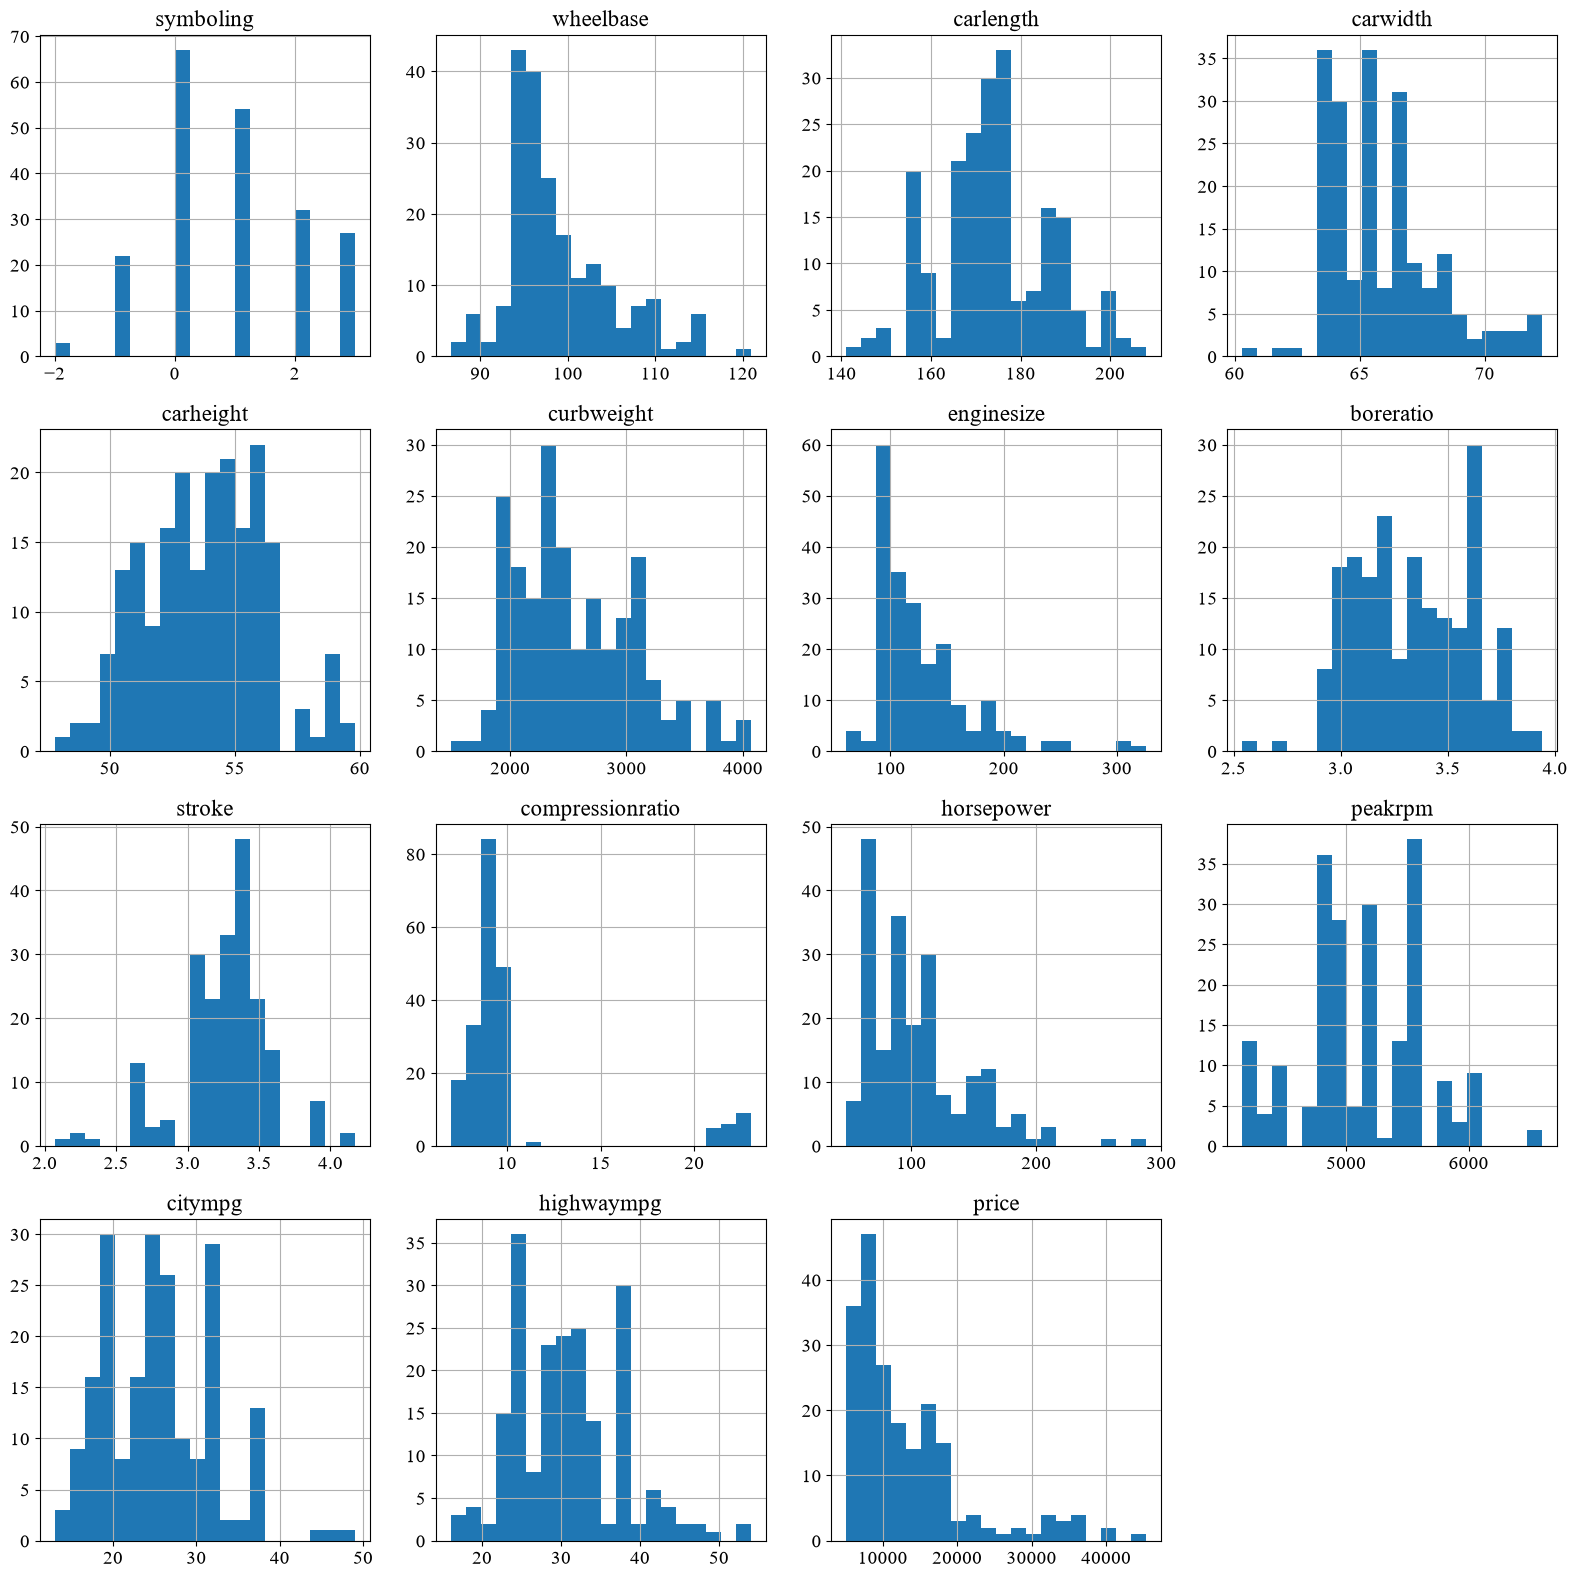

car_ID              0
symboling           0
wheelbase           1
carlength           0
carwidth            0
carheight           0
curbweight          0
enginesize          5
boreratio           0
stroke              3
compressionratio    9
horsepower          2
peakrpm             2
citympg             3
highwaympg          2
price               3
Name: Кількість значень за межами 3 sigma, dtype: int64

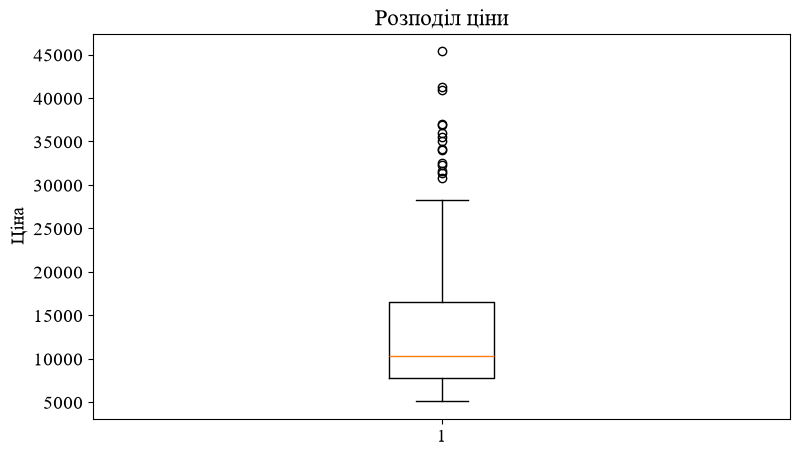

In [2]:
# Завантажити Car Price Prediction з Kaggle. Перевірити дублікати, пропущені дані, симетричність розподілів та викиди.
df=pd.read_csv(data_path('CarPrice_Assignment.csv'))
print('Джерело: https://www.kaggle.com/datasets/hellbuoy/car-price-prediction')
display(df.head());print(df.shape);display(df.dtypes)
display(df.isna().sum());print('Дублікати:',df.duplicated().sum())
df=df.drop_duplicates().copy()
num=df.select_dtypes(include='number')
display(num.skew().sort_values(ascending=False).rename('Асиметрія'))
num.drop(columns='car_ID').hist(bins=20,figsize=(16,16));plt.tight_layout();plt.show()
z=(num-num.mean())/num.std()
display((z.abs()>3).sum().rename('Кількість значень за межами 3 sigma'))
plt.boxplot(df['price']);plt.ylabel('Ціна');plt.title('Розподіл ціни');plt.show()

symboling            0
wheelbase            0
carlength            0
carwidth             0
carheight            0
curbweight           0
enginesize           2
boreratio            0
stroke               2
compressionratio    15
horsepower           1
peakrpm              0
citympg              0
highwaympg           0
Name: Крайні викиди за 3 IQR, dtype: int64

Вилучено навчальних рядків із 3 або більше крайніми ознаками: 0


,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg
symboling,1.000000,-0.527692,-0.332119,-0.244491,-0.518722,-0.208474,-0.092735,-0.147258,-0.000919,-0.146148,0.061062,0.240016,-0.021547,0.028702
wheelbase,-0.527692,1.000000,0.873328,0.816037,0.559552,0.790324,0.624471,0.495220,0.184598,0.153047,0.421208,-0.300798,-0.510444,-0.571916
carlength,-0.332119,0.873328,1.000000,0.861344,0.477974,0.884687,0.705473,0.608498,0.154944,0.080945,0.592204,-0.253418,-0.691960,-0.712324
carwidth,-0.244491,0.816037,0.861344,1.000000,0.276726,0.871119,0.750981,0.547644,0.216120,0.084928,0.668603,-0.151730,-0.659791,-0.691572
carheight,-0.518722,0.559552,0.477974,0.276726,1.000000,0.292842,0.098156,0.153089,-0.112972,0.204193,-0.069691,-0.277810,-0.080040,-0.117477
curbweight,-0.208474,0.790324,0.884687,0.871119,0.292842,1.000000,0.854567,0.633244,0.212406,0.034289,0.766572,-0.217668,-0.772092,-0.802905
enginesize,-0.092735,0.624471,0.705473,0.750981,0.098156,0.854567,1.000000,0.593297,0.262443,-0.060342,0.797408,-0.235308,-0.653830,-0.679124
boreratio,-0.147258,0.495220,0.608498,0.547644,0.153089,0.633244,0.593297,1.000000,-0.030891,-0.094035,0.579565,-0.224820,-0.586075,-0.581426
stroke,-0.000919,0.184598,0.154944,0.216120,-0.112972,0.212406,0.262443,-0.030891,1.000000,0.132942,0.153605,-0.026115,-0.093670,-0.091075
compressionratio,-0.146148,0.153047,0.080945,0.084928,0.204193,0.034289,-0.060342,-0.094035,0.132942,1.000000,-0.273364,-0.392142,0.386886,0.345762


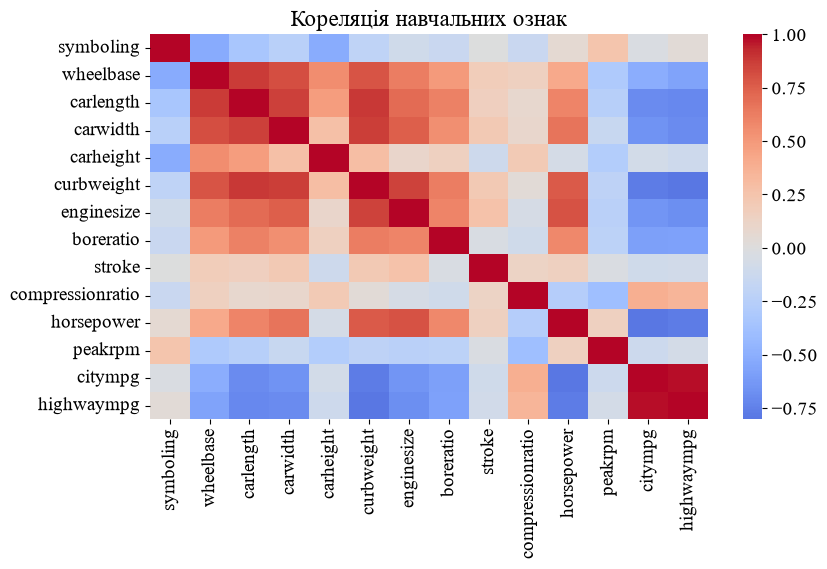

Збережені числові ознаки: ['symboling', 'wheelbase', 'carheight', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg']
Вилучені корельовані або сталі: ['carlength', 'carwidth', 'curbweight', 'enginesize', 'highwaympg']


,До,Після Yeo-Johnson
boreratio,-0.016343,0.002665
carheight,0.117386,0.001746
carlength,0.127672,NaN
carwidth,0.997893,NaN
citympg,0.728073,0.010723
compressionratio,2.724490,0.012451
curbweight,0.692024,NaN
enginesize,1.871083,NaN
highwaympg,0.580309,NaN
horsepower,1.316682,0.046886


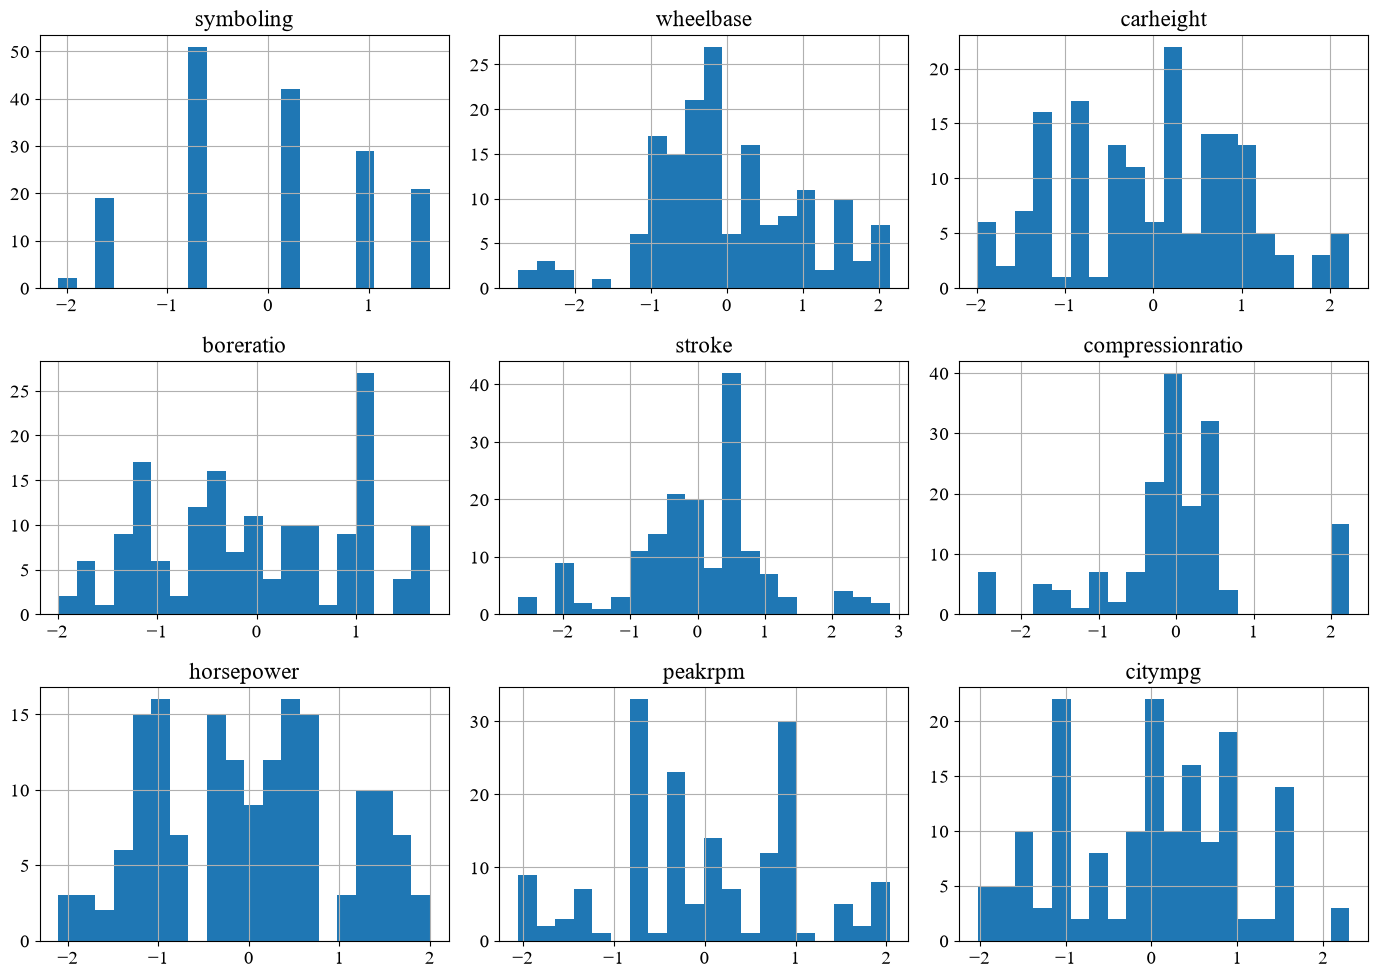

Yeo-Johnson зменшує асиметрію, але не гарантує ідеальної симетрії. Рідкі крайні значення додатково обмежено навчальними 1-м і 99-м процентилями.


In [3]:
# Підготовка: поділ на train/test, дослідження викидів та кореляції тільки на train; симетризація і кодування категорій.
from sklearn.preprocessing import PowerTransformer
from sklearn.compose import TransformedTargetRegressor
from sklearn.svm import SVR
from sklearn.base import BaseEstimator,TransformerMixin
from sklearn.feature_selection import VarianceThreshold
df['brand']=df.CarName.str.split().str[0].replace({'maxda':'mazda','porcshce':'porsche','toyouta':'toyota','vokswagen':'volkswagen','vw':'volkswagen'})
X=df.drop(columns=['price','car_ID','CarName']);y=df.price
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=25)
numeric=X_train.select_dtypes(include='number').columns.tolist()
categorical=X_train.select_dtypes(exclude='number').columns.tolist()
q1=X_train[numeric].quantile(0.25);q3=X_train[numeric].quantile(0.75);iqr=q3-q1
outliers=((X_train[numeric]<q1-3*iqr)|(X_train[numeric]>q3+3*iqr)) & (iqr>0)
display(outliers.sum().rename('Крайні викиди за 3 IQR'))
keep=(outliers.sum(axis=1)<3)
print('Вилучено навчальних рядків із 3 або більше крайніми ознаками:',int((~keep).sum()))
X_train=X_train.loc[keep];y_train=y_train.loc[keep]
display(X_train[numeric].corr())
sns.heatmap(X_train[numeric].corr(),cmap='coolwarm',center=0);plt.title('Кореляція навчальних ознак');plt.show()
class NumericPrep(BaseEstimator,TransformerMixin):
    def fit(self,X,y=None):
        X=np.asarray(X,dtype=float)
        self.fill_=SimpleImputer().fit(X)
        X=self.fill_.transform(X)
        self.low_=np.quantile(X,0.01,axis=0);self.high_=np.quantile(X,0.99,axis=0)
        X=np.clip(X,self.low_,self.high_)
        corr=pd.DataFrame(X).corr().abs()
        upper=corr.where(np.triu(np.ones(corr.shape),1).astype(bool))
        self.keep_=[i for i in range(X.shape[1]) if not (upper.iloc[:,i]>0.85).any() and np.std(X[:,i])>0]
        self.power_=PowerTransformer(method='yeo-johnson').fit(X[:,self.keep_])
        return self
    def transform(self,X):
        X=self.fill_.transform(np.asarray(X,dtype=float))
        X=np.clip(X,self.low_,self.high_)
        return self.power_.transform(X[:,self.keep_])
prep=ColumnTransformer([('num',NumericPrep(),numeric),('cat',Pipeline([('fill',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),categorical)])
inspect=NumericPrep().fit(X_train[numeric])
print('Збережені числові ознаки:',[numeric[i] for i in inspect.keep_])
print('Вилучені корельовані або сталі:',[n for i,n in enumerate(numeric) if i not in inspect.keep_])
after=pd.DataFrame(inspect.transform(X_train[numeric]),columns=[numeric[i] for i in inspect.keep_])
display(pd.DataFrame({'До':X_train[numeric].skew(),'Після Yeo-Johnson':after.skew()}))
after.hist(bins=20,figsize=(14,10));plt.tight_layout();plt.show()
print('Yeo-Johnson зменшує асиметрію, але не гарантує ідеальної симетрії. Рідкі крайні значення додатково обмежено навчальними 1-м і 99-м процентилями.')

In [4]:
# Побудувати лінійну, Ridge, Lasso, Random Forest, Gradient Boosting і SVR. Вивести метрики та визначити придатність моделей.
models={'Лінійна':LinearRegression(),'Ridge':Ridge(alpha=10),'Lasso':Lasso(alpha=0.001,max_iter=30000),'Випадковий ліс':RandomForestRegressor(n_estimators=150,min_samples_leaf=2,random_state=25,n_jobs=1),'Градієнтний бустинг':GradientBoostingRegressor(n_estimators=150,max_depth=2,random_state=25),'SVR':SVR(C=10,epsilon=0.1)}
fitted={};rows=[]
cv=KFold(n_splits=5,shuffle=True,random_state=25)
from sklearn.model_selection import cross_val_score
for name,model in models.items():
    reg=TransformedTargetRegressor(regressor=Pipeline([('pre',prep),('model',model)]),func=np.log1p,inverse_func=np.expm1)
    cv_mse=-cross_val_score(reg,X_train,y_train,cv=cv,scoring='neg_mean_squared_error').mean()
    reg.fit(X_train,y_train);fitted[name]=reg
    p=reg.predict(X_test)
    rows.append([name,cv_mse,mean_squared_error(y_test,p),r2_score(y_test,p)])
results=pd.DataFrame(rows,columns=['Модель','CV MSE','Test MSE','Test R2']);display(results)
best_name=results.loc[results['CV MSE'].idxmin(),'Модель']
print('Найкраща за CV MSE:',best_name)
print('Усі шість перелічених регресійних моделей можна будувати для числової ціни. Класифікатор LogisticRegression тут не підходить без зміни постановки задачі. Забороняти одну з перелічених регресій немає підстав.')

,Модель,CV MSE,Test MSE,Test R2
0,Лінійна,8.536324e+06,8.598553e+06,0.848125
1,Ridge,1.024408e+07,8.397789e+06,0.851671
2,Lasso,7.952385e+06,5.467527e+06,0.903428
3,Випадковий ліс,8.320778e+06,1.013281e+07,0.821025
4,Градієнтний бустинг,6.102247e+06,5.755457e+06,0.898342
5,SVR,9.372085e+06,9.957279e+06,0.824126


Найкраща за CV MSE: Градієнтний бустинг
Усі шість перелічених регресійних моделей можна будувати для числової ціни. Класифікатор LogisticRegression тут не підходить без зміни постановки задачі. Забороняти одну з перелічених регресій немає підстав.


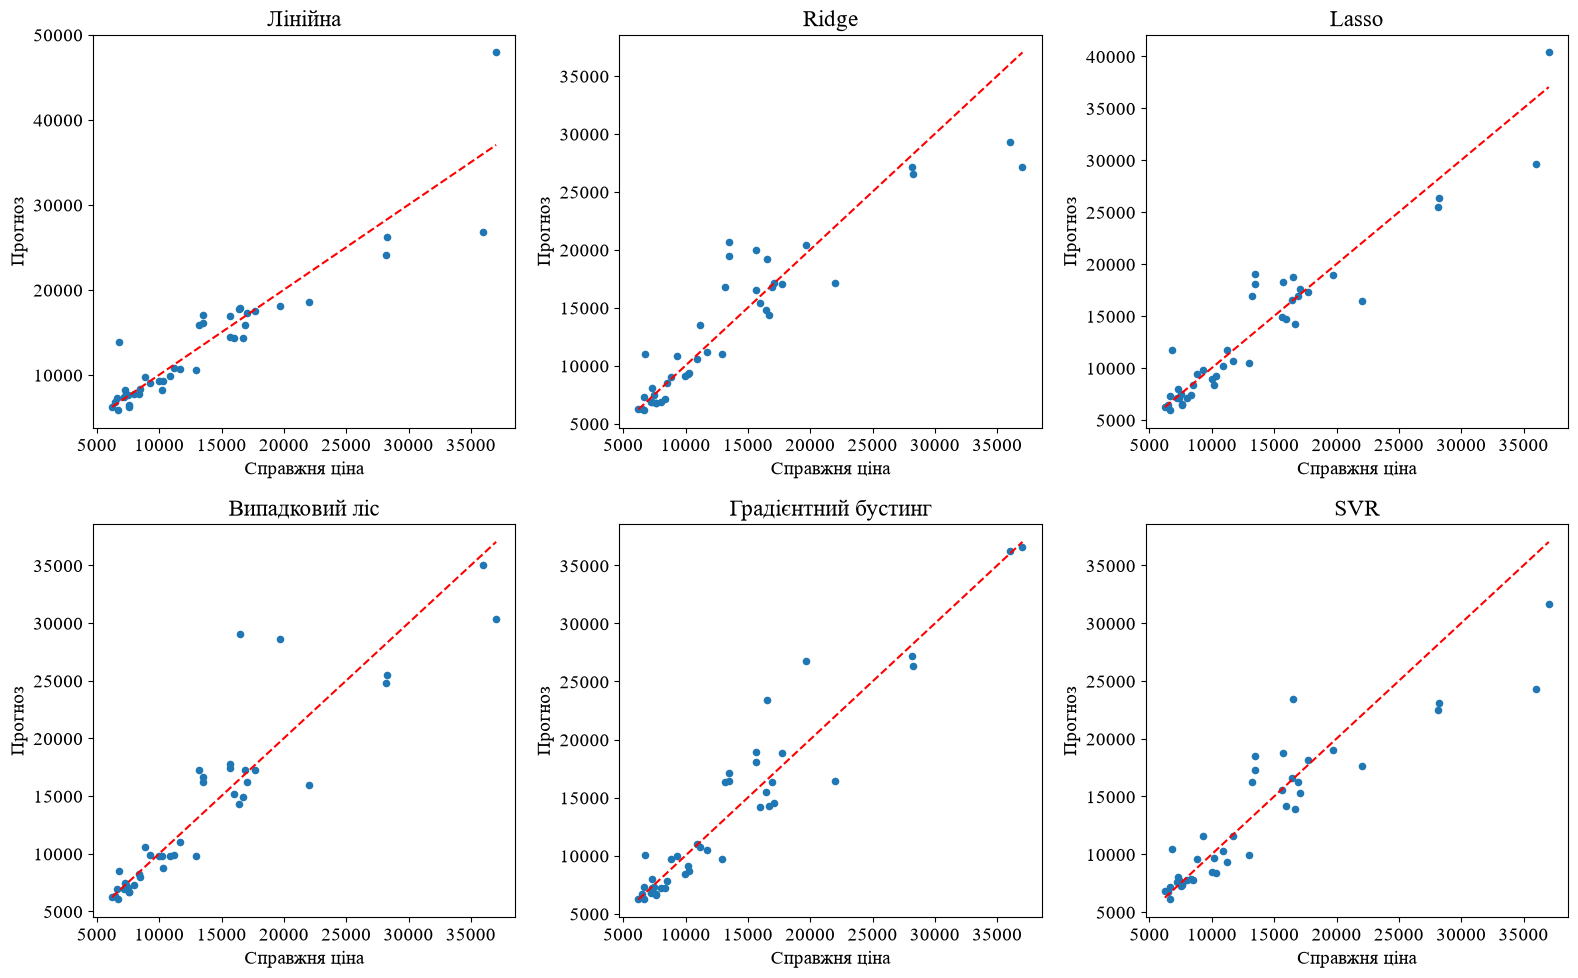

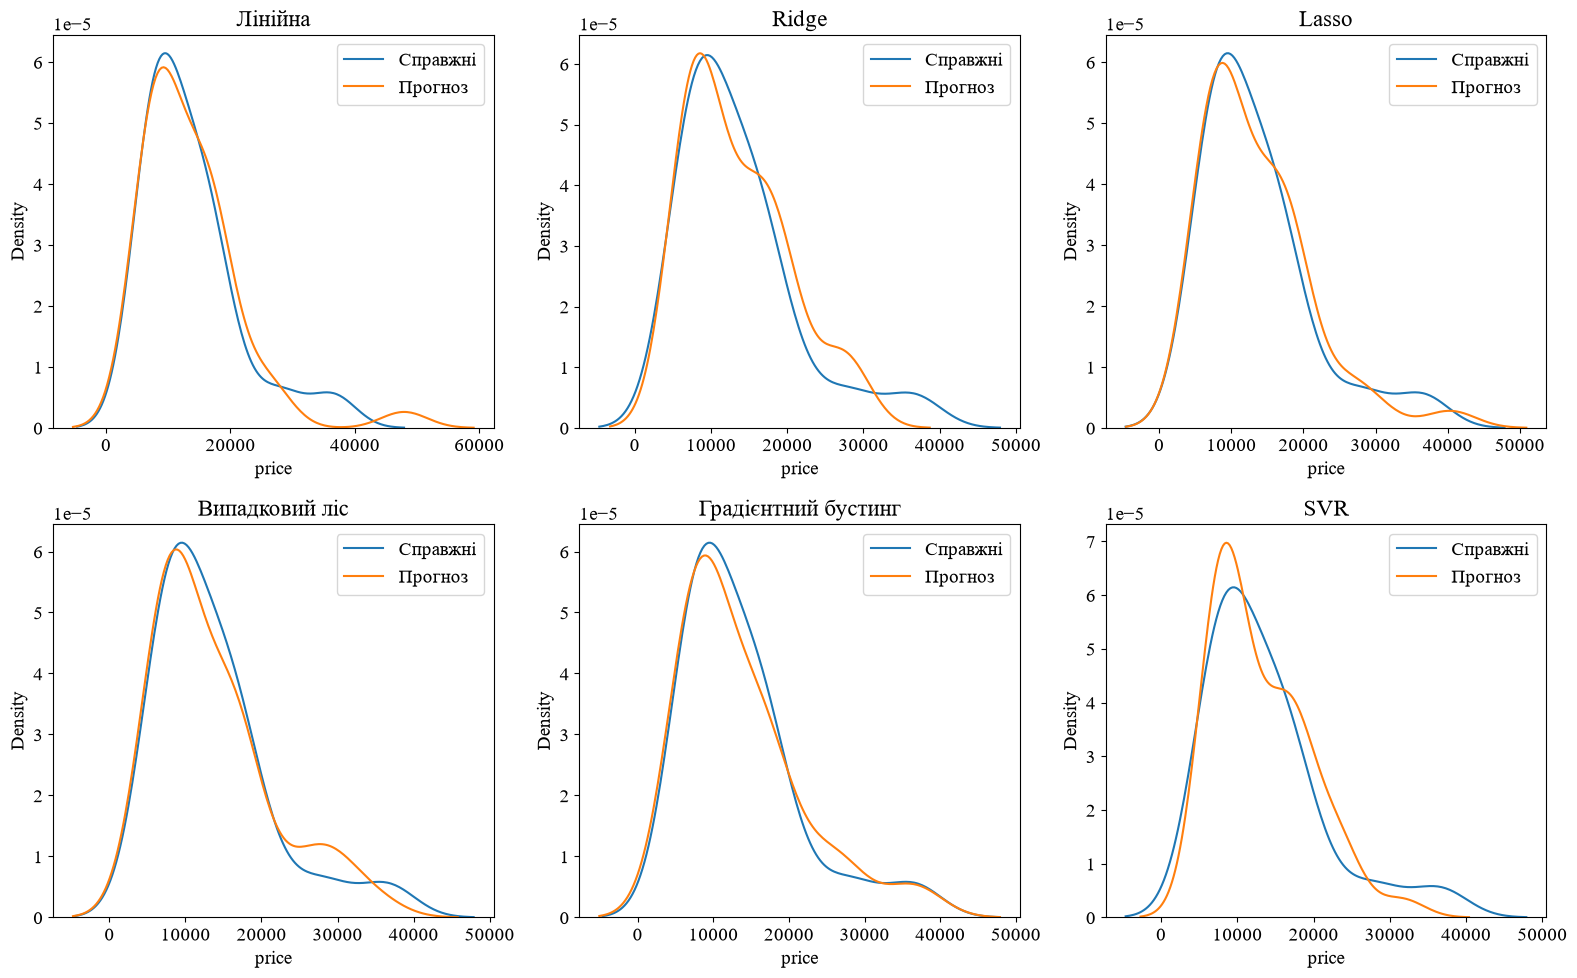

,ID,Справжня ціна,Прогноз Random Forest
120,121,6229.0,6256.891291
176,177,10898.0,9798.634347
96,97,7499.0,7051.706811
59,60,8845.0,10532.327575
40,41,10295.0,8755.126259
68,69,28248.0,25451.500538
161,162,8358.0,8226.582764
58,59,15645.0,17751.117101
41,42,12945.0,9794.246560
26,27,7609.0,6650.882234


In [5]:
# Графіки справжніх та прогнозованих значень і їхніх розподілів для всіх моделей. Прогноз Random Forest для 10 випадкових ID.
fig,axes=plt.subplots(2,3,figsize=(16,10))
for ax,(name,model) in zip(axes.flat,fitted.items()):
    p=model.predict(X_test)
    ax.scatter(y_test,p,s=20);ax.plot([y_test.min(),y_test.max()],[y_test.min(),y_test.max()],'r--')
    ax.set(title=name,xlabel='Справжня ціна',ylabel='Прогноз')
plt.tight_layout();plt.show()
fig,axes=plt.subplots(2,3,figsize=(16,10))
for ax,(name,model) in zip(axes.flat,fitted.items()):
    sns.kdeplot(y_test,ax=ax,label='Справжні')
    sns.kdeplot(model.predict(X_test),ax=ax,label='Прогноз')
    ax.set_title(name);ax.legend()
plt.tight_layout();plt.show()
sample=X_test.sample(10,random_state=25)
display(pd.DataFrame({'ID':df.loc[sample.index,'car_ID'],'Справжня ціна':y_test.loc[sample.index],'Прогноз Random Forest':fitted['Випадковий ліс'].predict(sample)}))

In [6]:
# Висновок. Проаналізовано пропуски, викиди, асиметрію та кореляцію цін автомобілів. Для запобігання витоку параметри обробки визначаються на навчальних даних і всередині фолдів CV. Порівняно шість моделей за MSE і R2, показано розподіли прогнозів та 10 прикладів. Найкраща за CV модель і її тестові метрики наведені у таблиці.